# Movie Recommendation Systems | Assignment 8

**Juan Luna Santibanez**

Miami Dade College | CAI2100C-2267-6908 | Machine Learning Foundations

**Professor Beth Muturi**

**Goal:** Build and compare content-based and collaborative movie recommendation systems using the IMDb Extensive dataset.

## Dataset

I use the IMDb Extensive dataset linked in the assignment. The MovieLens data used in the class example has a different structure. Download **IMDb movies.csv** and **IMDb ratings.csv** from [Kaggle](https://www.kaggle.com/datasets/stefanoleone992/imdb-extensive-dataset), then upload them to Colab, add the dataset in Kaggle or place both CSVs in a local `data/` directory.

IMDb ratings include **age/gender cohort averages**, not ratings by identifiable people. The collaborative approach below estimates cohort patterns rather than individual preferences.

## Data provenance and reproduction

I followed the two assignment tasks using **IMDb Extensive**. The source requested by the instructor is [Kaggle](https://www.kaggle.com/datasets/stefanoleone992/imdb-extensive-dataset). For the recorded run, the files were obtained via **GitHub mirror of Kaggle IMDb Extensive (immutable commit)**. The original CSV files are not redistributed in this GitHub portfolio. The exact file checksums and row counts appear in [dataset provenance](../docs/IMDb_DATA_PROVENANCE.json).

This is the IMDb dataset for the **final assignment**, not the separate MovieLens classroom demonstration.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print('Ready for the IMDb movie dataset.')

Ready for the IMDb movie dataset.


## Methods

I keep the implementation in this notebook so it works in Colab without importing a custom local package. The same functions are available in `src/recommenders.py` in the repository.

In [2]:
"""Movie recommendations for IMDb Extensive. Demographic averages are not personal ratings."""
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
COHORTS={"Women 18-29":("females_18age_avg_vote","females_18age_votes"),"Women 30-44":("females_30age_avg_vote","females_30age_votes"),"Women 45+":("females_45age_avg_vote","females_45age_votes"),"Men 18-29":("males_18age_avg_vote","males_18age_votes"),"Men 30-44":("males_30age_avg_vote","males_30age_votes"),"Men 45+":("males_45age_avg_vote","males_45age_votes")}
def find_data(roots=(".",)):
    paths={}
    for name in ("IMDb movies.csv","IMDb ratings.csv"):
        found=[]
        for root in map(Path,roots):
            found.append(root/name)
            if root.is_dir():found.extend(root.glob("**/"+name))
        paths[name]=next((p for p in found if p.is_file()),None)
    if any(p is None for p in paths.values()):
        raise FileNotFoundError("Download IMDb movies.csv and IMDb ratings.csv from https://www.kaggle.com/datasets/stefanoleone992/imdb-extensive-dataset")
    return paths
def load_imdb(paths,limit=3000,min_votes=1000):
    m=pd.read_csv(paths["IMDb movies.csv"],low_memory=False)
    r=pd.read_csv(paths["IMDb ratings.csv"],low_memory=False)
    required={"imdb_title_id","title","genre","description","director","actors","votes","avg_vote"}
    ratings_required={"imdb_title_id"}|{x for pair in COHORTS.values() for x in pair}
    if required-set(m):raise ValueError("IMDb movie columns missing: "+str(required-set(m)))
    if ratings_required-set(r):raise ValueError("IMDb rating columns missing: "+str(ratings_required-set(r)))
    m["votes"]=pd.to_numeric(m.votes,errors="coerce").fillna(0)
    m["avg_vote"]=pd.to_numeric(m.avg_vote,errors="coerce")
    m=m[m.votes.ge(min_votes)&m.title.notna()&m.imdb_title_id.notna()]
    m=m.sort_values("votes",ascending=False).drop_duplicates("imdb_title_id").head(limit).copy()
    for k in ("title","genre","description","director","actors"):m[k]=m[k].fillna("").astype(str)
    out=m.merge(r[["imdb_title_id"]+[x for pair in COHORTS.values() for x in pair]].drop_duplicates("imdb_title_id"),on="imdb_title_id",how="left",validate="one_to_one")
    if len(out)<5:raise ValueError("At least five IMDb movies are required after filtering")
    return out.reset_index(drop=True)
def content_features(movies):
    text=movies.genre.str.replace(","," ",regex=False)+" "+movies.director.str.replace(","," ",regex=False)+" "+movies.actors.str.replace(","," ",regex=False)+" "+movies.description
    return TfidfVectorizer(stop_words="english",ngram_range=(1,2),max_features=6000).fit_transform(text)
def content_recommend(movies,features,title,n=10):
    matched=np.flatnonzero(movies.title.str.casefold().eq(title.casefold()))
    if not len(matched):raise KeyError("Unknown selected IMDb title: "+title)
    i=int(matched[0]);sim=(features@features[i].T).toarray().ravel()
    ids=np.argsort(-sim,kind="stable");ids=ids[ids!=i][:n]
    result=movies.iloc[ids][["title","genre","imdb_title_id","avg_vote"]].copy()
    result["similarity"]=sim[ids]
    return result.reset_index(drop=True)
def cohort_matrix(movies,min_votes=30):
    rows=[]
    for mean,count in COHORTS.values():
        v=pd.to_numeric(movies[mean],errors="coerce")
        votes=pd.to_numeric(movies[count],errors="coerce").fillna(0)
        rows.append(v.where(v.between(1,10)&votes.ge(min_votes)).to_numpy(float))
    return pd.DataFrame(rows,index=list(COHORTS),columns=movies.imdb_title_id.tolist())
def cohort_similarity(matrix,min_overlap=15):
    x=matrix.to_numpy(float);n=x.shape[0];out=np.eye(n)
    for i in range(n):
        for j in range(i+1,n):
            mask=np.isfinite(x[i])&np.isfinite(x[j])
            corr=float(np.corrcoef(x[i,mask],x[j,mask])[0,1]) if mask.sum()>=min_overlap and np.std(x[i,mask])>1e-10 and np.std(x[j,mask])>1e-10 else 0.
            out[i,j]=out[j,i]=np.clip(corr,-1,1)
    return pd.DataFrame(out,index=matrix.index,columns=matrix.index)
def cohort_predict(matrix,sim,row,col):
    x=matrix.to_numpy(float);means=np.nanmean(x,axis=1);average=float(np.nanmean(x))
    base=means[row] if np.isfinite(means[row]) else average
    weights=sim.iloc[row].to_numpy(float).copy();weights[row]=0
    use=(weights>0)&np.isfinite(x[:,col])&np.isfinite(means)
    if not use.any():return float(np.clip(base,1,10))
    predicted=base+np.dot(weights[use],x[use,col]-means[use])/weights[use].sum()
    return float(np.clip(predicted,1,10))
def cohort_recommend(movies,matrix,cohort="Women 18-29",n=10):
    if cohort not in matrix.index:raise KeyError(cohort)
    row=list(matrix.index).index(cohort);sim=cohort_similarity(matrix)
    available=[j for j in range(matrix.shape[1]) if pd.isna(matrix.iloc[row,j]) and matrix.iloc[:,j].notna().sum()>=2]
    unseen=bool(available)
    if not unseen:available=[j for j in range(matrix.shape[1]) if matrix.iloc[:,j].notna().sum()>=3]
    if not available:raise ValueError("Not enough cohort averages for predictions")
    estimates=np.array([cohort_predict(matrix,sim,row,j) for j in available])
    order=np.argsort(-estimates)[:n]
    keys=matrix.columns[np.array(available)[order]]
    result=movies.set_index("imdb_title_id").loc[keys,["title","genre","avg_vote"]].copy()
    result["estimated_cohort_average"]=estimates[order]
    result.attrs["note"]="Missing-cell estimates" if unseen else "Descriptive group averages, not individual preferences"
    return result.reset_index()
def evaluate_cohort(matrix,seed=42,fraction=0.15):
    observed=np.argwhere(np.isfinite(matrix.to_numpy(float)))
    if len(observed)<60:raise ValueError("Not enough cohort observations")
    rng=np.random.default_rng(seed);rng.shuffle(observed)
    train=matrix.copy();actual=[];target=max(1,round(len(observed)*fraction))
    for i,j in observed:
        if len(actual)>=target:break
        if train.iloc[i].notna().sum()<=15 or train.iloc[:,j].notna().sum()<=2:continue
        actual.append((int(i),int(j),float(matrix.iloc[i,j])));train.iloc[i,j]=np.nan
    if not actual:raise ValueError("Could not create validation subset")
    sim=cohort_similarity(train)
    errors=np.array([cohort_predict(train,sim,i,j)-truth for i,j,truth in actual])
    return {"held_out":len(actual),"MAE":float(np.mean(abs(errors))),"RMSE":float(np.sqrt(np.mean(errors**2)))}


## Load the IMDb files

In [3]:
paths=find_data(['.','..','data','/content','/kaggle/input','/kaggle/working'])
movies=load_imdb(paths,limit=3000,min_votes=1000)
print('IMDb titles:',len(movies))
display(movies[['title','genre','votes','avg_vote']].head())

IMDb titles: 3000


,title,genre,votes,avg_vote
0,Le ali della libertà,Drama,2278845,9.3
1,Il cavaliere oscuro,"Action, Crime, Drama",2241615,9.0
2,Inception,"Action, Adventure, Sci-Fi",2002816,8.8
3,Fight Club,Drama,1807440,8.8
4,Pulp Fiction,"Crime, Drama",1780147,8.9


## Task 1 — Content-Based Recommendation

I use TF-IDF to represent the description, genre, director and actors for each movie, then use cosine similarity to find related titles.

In [4]:
features=content_features(movies)
selected=str(movies.iloc[0].title)
recommendations=content_recommend(movies,features,selected,10)
print('Selected title:',selected)
display(recommendations)

Selected title: Le ali della libertà


,title,genre,imdb_title_id,avg_vote,similarity
0,Glory - Uomini di gloria,"Biography, Drama, History",tt0097441,7.8,0.156056
1,Hurricane - Il grido dell'innocenza,"Biography, Drama, Sport",tt0174856,7.6,0.123435
2,Aliens - Scontro finale,"Action, Adventure, Sci-Fi",tt0090605,8.3,0.122481
3,Wanted - Scegli il tuo destino,"Action, Crime, Fantasy",tt0493464,6.7,0.122251
4,SpongeBob - Il film,"Animation, Action, Adventure",tt0345950,7.1,0.121467
5,Highwaymen - L'ultima imboscata,"Biography, Crime, Drama",tt1860242,6.9,0.119276
6,Nome in codice: Broken Arrow,"Action, Adventure, Thriller",tt0115759,6.1,0.116445
7,Seven,"Crime, Drama, Mystery",tt0114369,8.6,0.114006
8,Non è mai troppo tardi,"Comedy, Drama",tt0825232,7.4,0.113258
9,A spasso con Daisy,Drama,tt0097239,7.3,0.113241


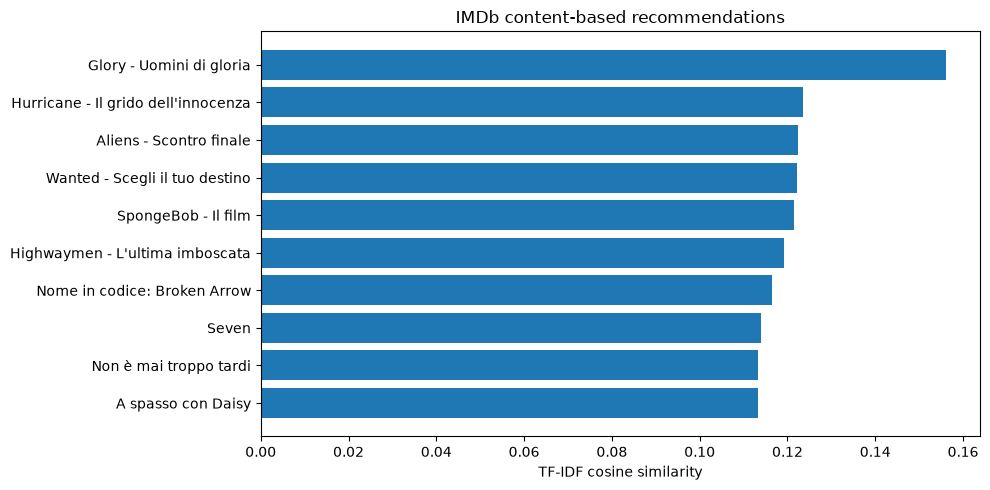

In [5]:
fig,ax=plt.subplots(figsize=(10,5))
r=recommendations.iloc[::-1]
ax.barh(r.title.str.slice(0,42),r.similarity)
ax.set(title='IMDb content-based recommendations',xlabel='TF-IDF cosine similarity')
plt.tight_layout();plt.show()

## Task 2 — Collaborative Recommendation

IMDb provides ratings aggregated by audience cohort. I compare six audience-cohort rating patterns using Pearson correlation. This is a **cohort-level collaborative approximation**, not personalized user-rating SVD.

In [6]:
matrix=cohort_matrix(movies)
similarity=cohort_similarity(matrix)
print('Rating matrix:',matrix.shape)
display(similarity.round(3))

Rating matrix: (6, 3000)


,Women 18-29,Women 30-44,Women 45+,Men 18-29,Men 30-44,Men 45+
Women 18-29,1.000,0.978,0.915,0.940,0.923,0.894
Women 30-44,0.978,1.000,0.952,0.937,0.948,0.936
Women 45+,0.915,0.952,1.000,0.870,0.893,0.950
Men 18-29,0.940,0.937,0.870,1.000,0.984,0.935
Men 30-44,0.923,0.948,0.893,0.984,1.000,0.964
Men 45+,0.894,0.936,0.950,0.935,0.964,1.000


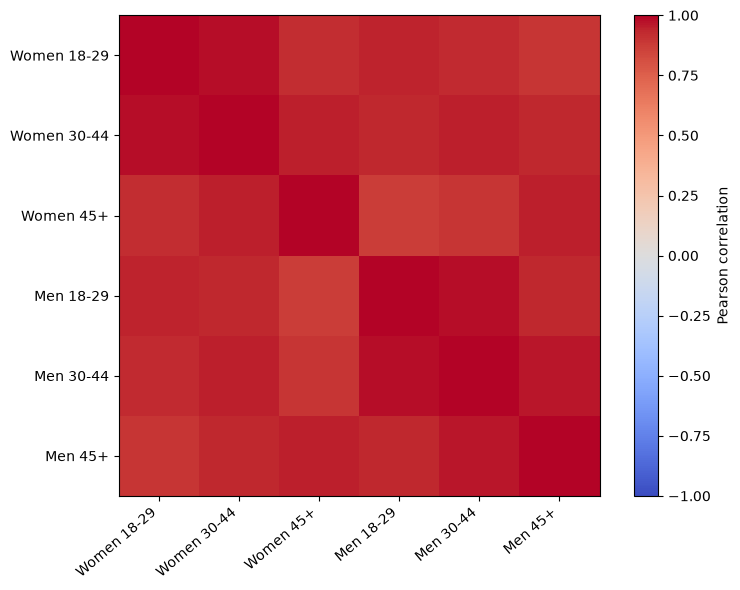

In [7]:
fig,ax=plt.subplots(figsize=(8,6))
image=ax.imshow(similarity.to_numpy(),vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(6),similarity.columns,rotation=40,ha='right')
ax.set_yticks(range(6),similarity.index)
fig.colorbar(image,ax=ax,label='Pearson correlation');plt.tight_layout();plt.show()

In [8]:
result=cohort_recommend(movies,matrix,'Women 18-29',n=10)
print(result.attrs['note'])
display(result)
print('Held-out cohort-mean validation:',evaluate_cohort(matrix))

Descriptive group averages, not individual preferences


,index,title,genre,avg_vote,estimated_cohort_average
0,tt0111161,Le ali della libertà,Drama,9.3,9.369949
1,tt0068646,Il padrino,"Crime, Drama",9.2,9.247216
2,tt0071562,Il padrino - Parte II,"Crime, Drama",9.0,9.047216
3,tt0108052,Schindler's List,"Biography, Drama, History",8.9,9.030874
4,tt0050083,La parola ai giurati,"Crime, Drama",8.9,8.990699
5,tt0167260,Il Signore degli Anelli - Il ritorno del re,"Action, Adventure, Drama",8.9,8.971838
6,tt0120737,Il Signore degli Anelli - La compagnia dell'An...,"Action, Adventure, Drama",8.8,8.930058
7,tt0468569,Il cavaliere oscuro,"Action, Crime, Drama",9.0,8.873832
8,tt0110912,Pulp Fiction,"Crime, Drama",8.9,8.867750
9,tt0109830,Forrest Gump,"Drama, Romance",8.8,8.831569


Held-out cohort-mean validation: {'held_out': 2700, 'MAE': 0.1836024875467409, 'RMSE': 0.24770389139957708}


## Short conclusion

Content-based filtering compares movie information. Collaborative filtering compares patterns in ratings. The IMDb dataset contains cohort averages, so my second model estimates group-level patterns and cannot claim to know a particular person's preferences. Both methods help me understand why different information produces different recommendations.